# Flow Matching with Scaled Sigma and Curved Path

In [1]:
%load_ext autoreload
%autoreload 2

$\alpha_t$ and $\beta_t$ are valid as long as
1. $\alpha_0 = 0$, $\alpha_1 = 1$.
2. $\beta_0 = 1$, $\beta_1 = 0$.

When $\alpha_t + \beta_t = 1$, the conditional path is straight. 

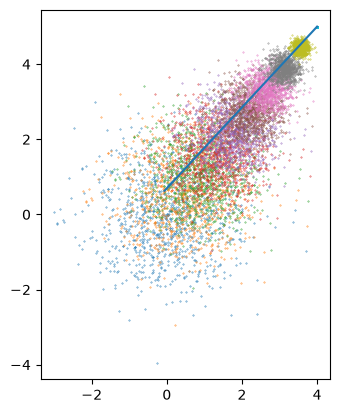

In [2]:
import numpy as np
import matplotlib.pyplot as plt

b = 1000
l = 10
x0 = np.random.randn(b, 2)[:, None, :]  # shape (b, 1, d)
z = np.array([[4, 5]])[:, None, :]      # shape (1, 1, d) 
t = np.linspace(0, 1, l)[None, :, None] # shape (1, l, 1)

s = 3
alpha = lambda t: t
beta = lambda t: 1 - t

xt = alpha(t) * z + beta(t) * x0    # shape (b, l, d)

fig, ax = plt.subplots()
for i in range(l):
    ax.scatter(xt[:, i, 0], xt[:, i, 1], s=0.1)

ax.plot(xt[0, :, 0], xt[0, :, 1])
ax.set_aspect('equal')

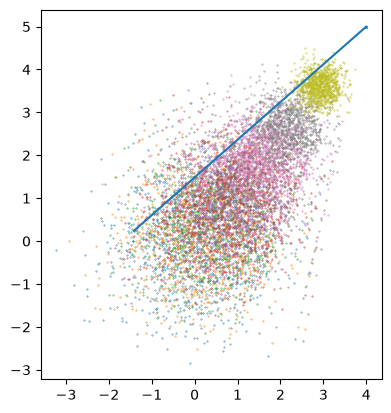

In [3]:
import numpy as np
import matplotlib.pyplot as plt

b = 1000
l = 10
x0 = np.random.randn(b, 2)[:, None, :]  # shape (b, 1, d)
z = np.array([[4, 5]])[:, None, :]      # shape (1, 1, d) 
t = np.linspace(0, 1, l)[None, :, None] # shape (1, l, 1)

s = 3
alpha = lambda t: t / (s - (s - 1) * t)
beta = lambda t: 1 - alpha(t)

xt = alpha(t) * z + beta(t) * x0    # shape (b, l, d)

fig, ax = plt.subplots()
for i in range(l):
    ax.scatter(xt[:, i, 0], xt[:, i, 1], s=0.1)

ax.plot(xt[0, :, 0], xt[0, :, 1])
ax.set_aspect('equal')

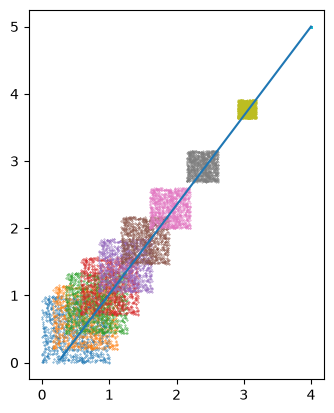

In [4]:
import numpy as np
import matplotlib.pyplot as plt

b = 1000
l = 10
x0 = np.random.rand(b, 2)[:, None, :]  # shape (b, 1, d)
z = np.array([[4, 5]])[:, None, :]      # shape (1, 1, d) 
t = np.linspace(0, 1, l)[None, :, None] # shape (1, l, 1)

s = 3
alpha = lambda t: t / (s - (s - 1) * t)
beta = lambda t: 1 - alpha(t)

xt = alpha(t) * z + beta(t) * x0    # shape (b, l, d)

fig, ax = plt.subplots()
for i in range(l):
    ax.scatter(xt[:, i, 0], xt[:, i, 1], s=0.1)

ax.plot(xt[0, :, 0], xt[0, :, 1])
ax.set_aspect('equal')

When $\alpha_t + \beta_t = 1$, the conditional path is curved.

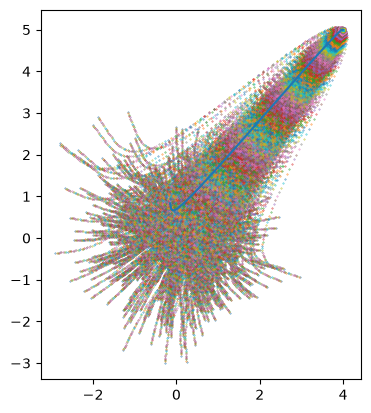

In [5]:
import numpy as np
import matplotlib.pyplot as plt

b = 1000
l = 100
x0 = np.random.randn(b, 2)[:, None, :]  # shape (b, 1, d)
z = np.array([[4, 5]])[:, None, :]      # shape (1, 1, d) 
t = np.linspace(0, 1, l)[None, :, None] # shape (1, l, 1)

s = 3
alpha = lambda t: np.sin(0.5 * np.pi * t)**5
beta = lambda t: 1 - t

xt = alpha(t) * z + beta(t) * x0    # shape (b, l, d)

fig, ax = plt.subplots()
for i in range(l):
    ax.scatter(xt[:, i, 0], xt[:, i, 1], s=0.1)

ax.plot(xt[0, :, 0], xt[0, :, 1])
ax.set_aspect('equal')

In [6]:
from generative_models.data import MoonsCirclesDataset
import matplotlib.pyplot as plt
from generative_models.trainer import FlowMatchingTrainer
from generative_models.model import FlowMatchingMLP
import torch

config = {
    'lr': 1e-3,
    'batch_size': 1000,
    'total_steps': 10000,
    'log': True,
    'project': 'OTFlowMatching',
    'name': 'mlp_lr_1e-3'
}

alpha = lambda t: torch.sin(0.5 * torch.pi * t)**5
beta = lambda t: 1 - t

dataset = MoonsCirclesDataset(n_samples=100000, noise_moons=0.05, noise_circles=0.04)
model = FlowMatchingMLP(2, [256, 256, 256, 2])
trainer = FlowMatchingTrainer(model, alpha, beta, dataset, config)

trainer.train()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: ron_chuxia (ron_chuxia_hsl) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


100%|██████████| 10000/10000 [00:33<00:00, 295.22it/s, loss=0.99]


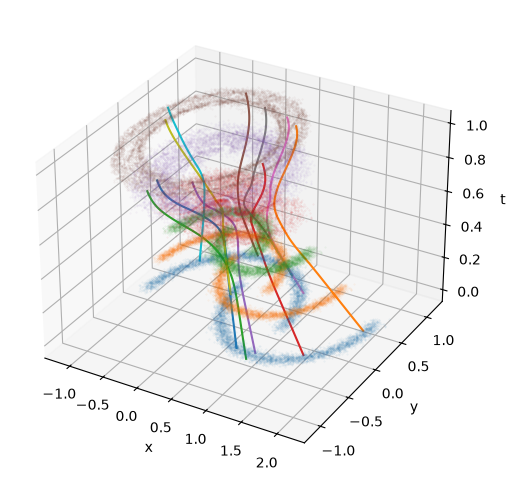

In [7]:
from generative_models.data import MoonsDataset
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

In [8]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

b = 10000
l = 100

ode = NeuralODE(model)
euler = Euler(ode=ode)

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot()
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
title = ax.set_title('')
scatter = ax.scatter([], [], s=0.1)

def update(frame):
    scatter.set_offsets(x_pred[:, frame, :])
    title.set_text(f'steps={frame}')
    return (scatter,)

ani = FuncAnimation(fig, update, frames=l, interval=20)

from IPython.display import HTML
plt.close(fig)  # Prevent a separate static plot.
HTML(ani.to_jshtml())

In [9]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

b = 10000

ode = NeuralODE(model)
euler = Euler(ode=ode)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot()
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
title = ax.set_title('')
scatter = ax.scatter([], [], s=0.1)

def update(frame):
    t = torch.linspace(0, 1, frame)[None, :].expand(b, frame)
    t1 = torch.ones((b, 1))
    t = torch.concat([t, t1], dim=1)    # shape (b, frame+1)

    dataset = MoonsDataset(n_samples=b, noise=0.05)
    x0 = dataset.x
    x0 = x0.to(trainer.device)
    t = t.to(trainer.device)
    with torch.no_grad():
        x_pred = euler.simulate_trajectory(x0, t, whole=False)   # shape (b, d)
    x_pred = x_pred.cpu().numpy()
    t = t.cpu().numpy()
    
    scatter.set_offsets(x_pred)
    title.set_text(f'total steps={frame}')
    return (scatter,)

ani = FuncAnimation(
    fig, update, frames=range(1, 30), interval=100, blit=True
)

from IPython.display import HTML
plt.close(fig)  # Prevent a separate static plot.
HTML(ani.to_jshtml())